# TD SESSION3 BASE VECTORIELLE - ML- DITI4

In [33]:
# Installation des dépendances
!pip install pillow chromadb open_clip_torch tqdm ipykernel

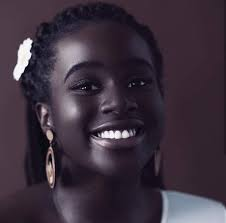

In [34]:
from PIL import Image
import glob

listeImages = []
for file_name in glob.glob("images/personnes/*.jpeg"):
    image = Image.open(file_name)
    listeImages.append(image)

display(listeImages[4])

In [35]:
import chromadb
from chromadb.utils.data_loaders import ImageLoader
from chromadb.utils.embedding_functions import OpenCLIPEmbeddingFunction

BV_chromabd = chromadb.PersistentClient(path="db_storePersonnes")

chargeImages = ImageLoader()
VectorisationImages = OpenCLIPEmbeddingFunction()

chromadb = BV_chromabd.get_or_create_collection(
    name="personnes",
    data_loader=chargeImages,
    embedding_function=VectorisationImages
)


In [36]:
import os

indexImage = []
CheminImages = []
dossierImages = "images/personnes"

for index, image_name in enumerate(sorted(os.listdir(dossierImages))):
    if image_name.endswith(".jpeg"):
        image_path = os.path.join(dossierImages, image_name)
        indexImage.append(str(index))
        CheminImages.append(image_path)

print(indexImage[:21])
print(CheminImages[:21])


['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20']
['images/personnes\\images (1).jpeg', 'images/personnes\\images (10).jpeg', 'images/personnes\\images (11).jpeg', 'images/personnes\\images (12).jpeg', 'images/personnes\\images (13).jpeg', 'images/personnes\\images (14).jpeg', 'images/personnes\\images (15).jpeg', 'images/personnes\\images (16).jpeg', 'images/personnes\\images (17).jpeg', 'images/personnes\\images (2).jpeg', 'images/personnes\\images (3).jpeg', 'images/personnes\\images (4).jpeg', 'images/personnes\\images (5).jpeg', 'images/personnes\\images (6).jpeg', 'images/personnes\\images (7).jpeg', 'images/personnes\\images (8).jpeg', 'images/personnes\\images (9).jpeg', 'images/personnes\\images.jpeg', 'images/personnes\\téléchargement (1).jpeg', 'images/personnes\\téléchargement (2).jpeg', 'images/personnes\\téléchargement.jpeg']


In [37]:
chromadb.add(ids=indexImage, uris=CheminImages)

In [38]:
chromadb.count()

21

In [44]:
rechercheParText = chromadb.query(
    query_texts=["femme Noir"],
    n_results=1,
    include=["uris", "distances"]
)

rechercheParText

{'ids': [['2']],
 'embeddings': None,
 'documents': None,
 'uris': [['images/personnes\\images (11).jpeg']],
 'included': ['uris', 'distances'],
 'data': None,
 'metadatas': None,
 'distances': [[0.6991404294967651]]}

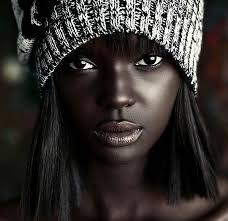

In [45]:
for image in rechercheParText["uris"][0]:
    display(Image.open(image))